Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.
Applying windowing and extracting statistical features (No Discretization)...

Starting LOSO Cross-Validation...

--- LOSO Results (Raw Windowed Features) ---
User debora: F1-Score = 0.8370
User jose_carlos: F1-Score = 0.6334
User katia: F1-Score = 0.5058
User wallace: F1-Score = 0.8489

OVERALL WEIGHTED F1-SCORE: 0.7498

Starting SHAP Analysis (this may take a moment)...


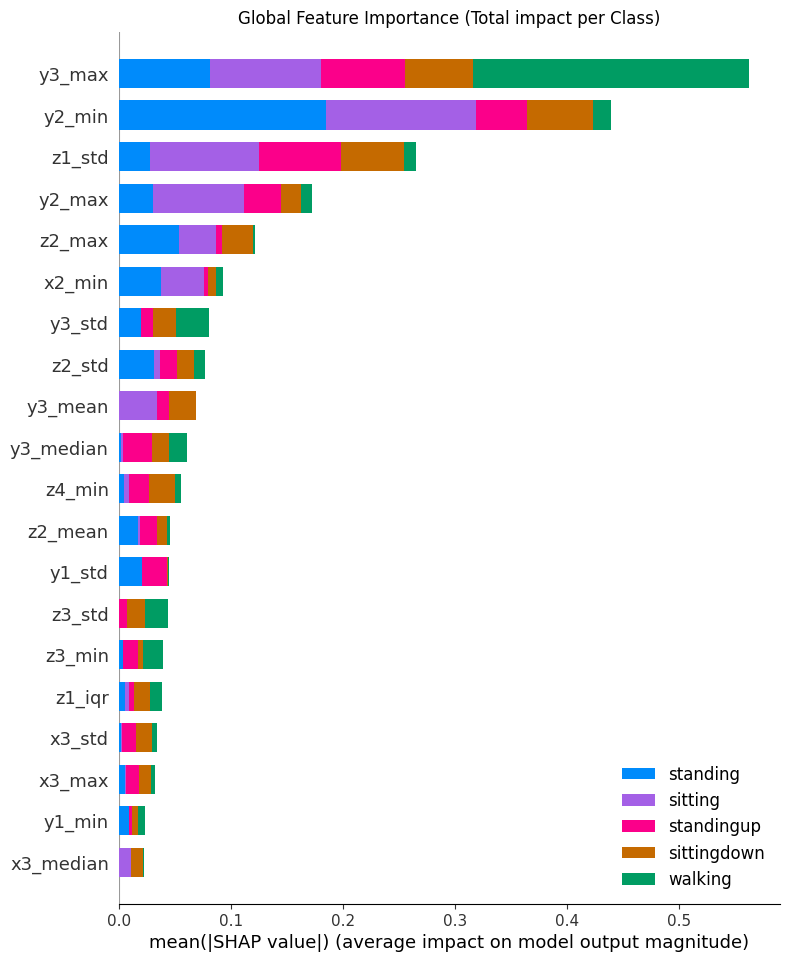


Visualizing Top Features for Class: sitting


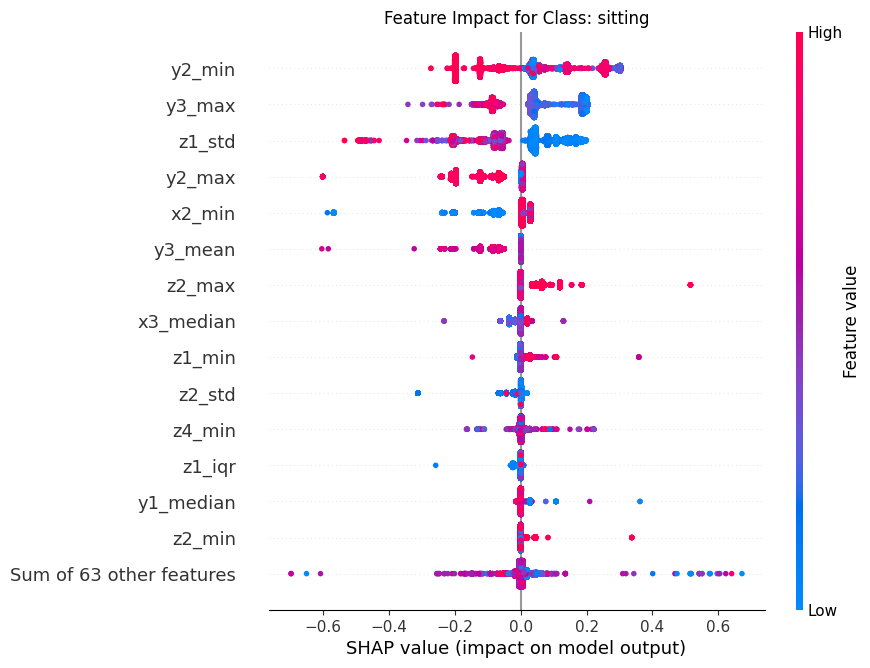


Visualizing Top Features for Class: sittingdown


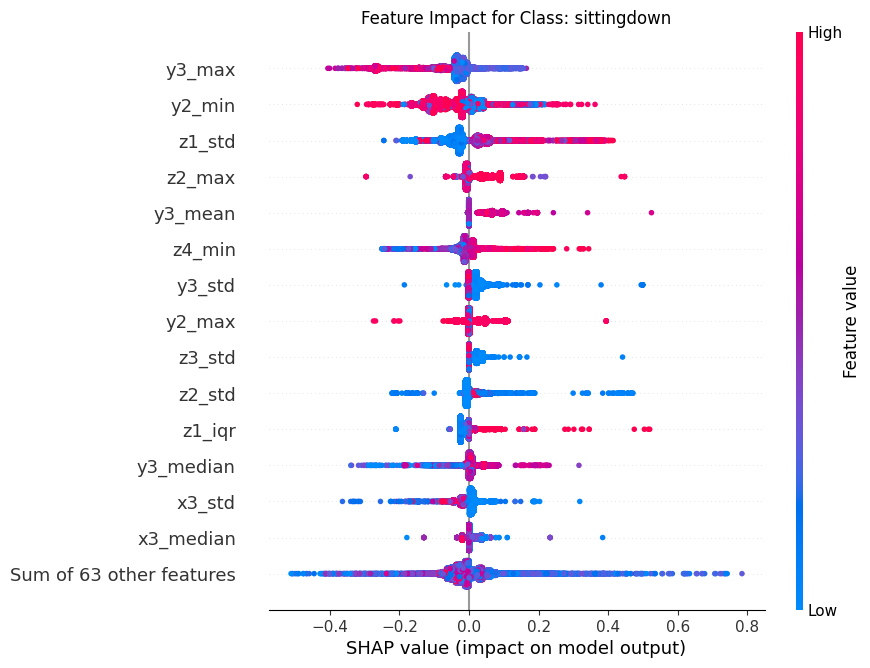


Visualizing Top Features for Class: standing


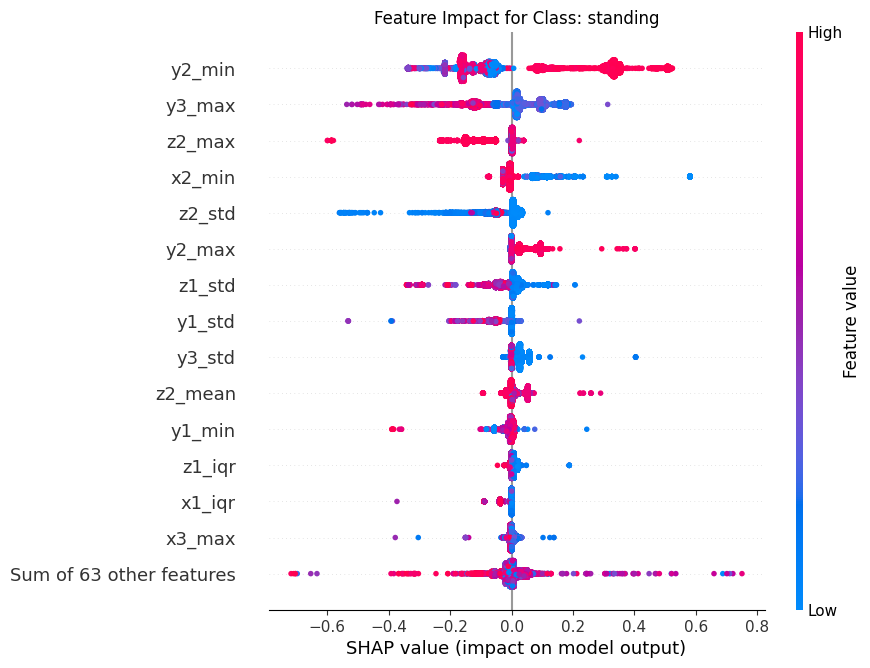


Visualizing Top Features for Class: standingup


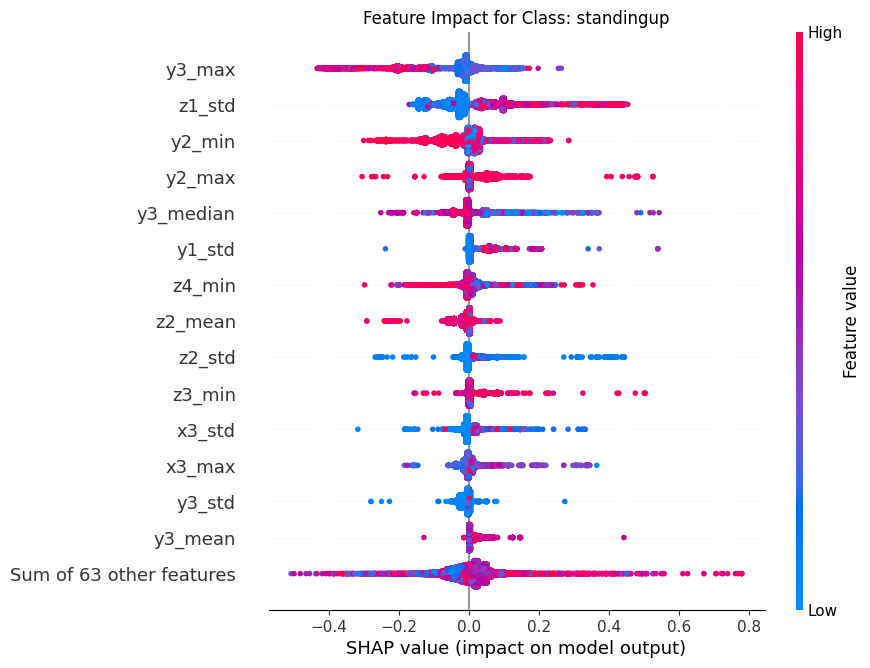


Visualizing Top Features for Class: walking


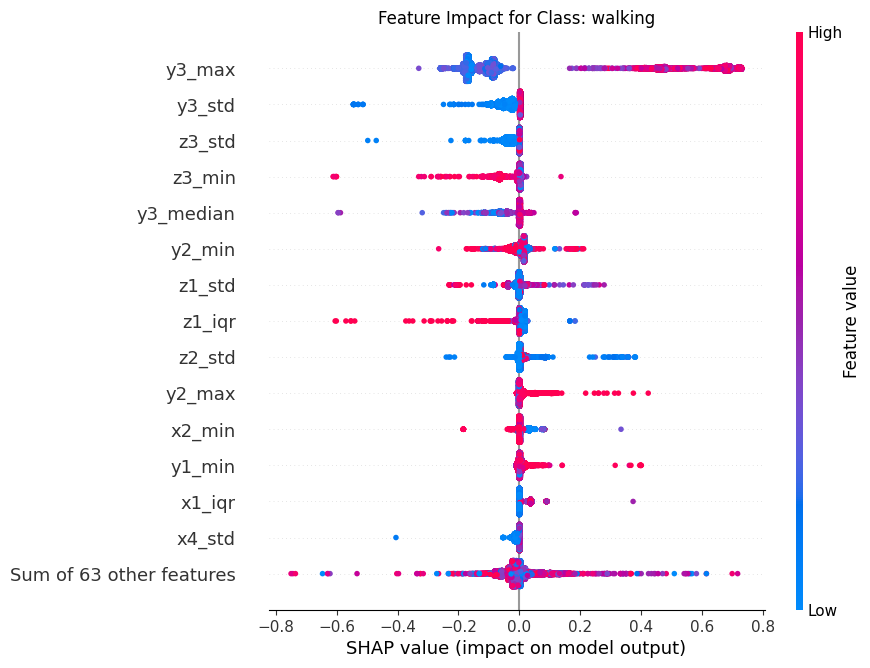

/tmp/ipykernel_13023/3227812567.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(20), x='Importance', y='Feature', palette='viridis', ax=ax1)
/tmp/ipykernel_13023/3227812567.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.tail(20), x='Importance', y='Feature', palette='rocket', ax=ax2)


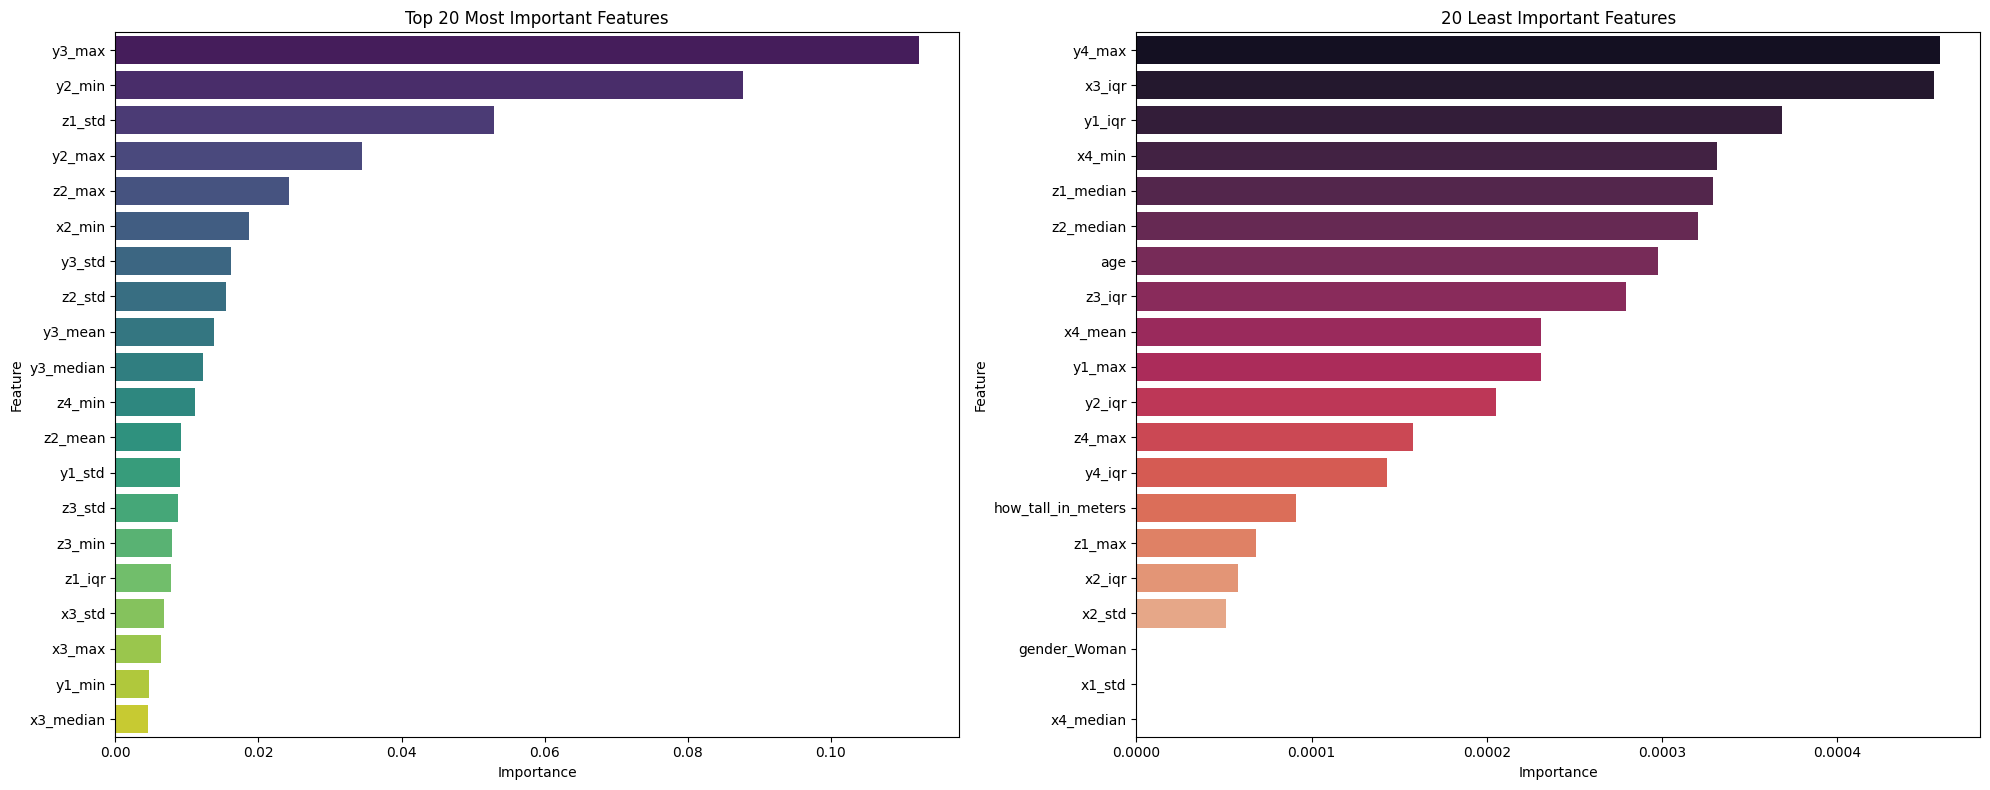

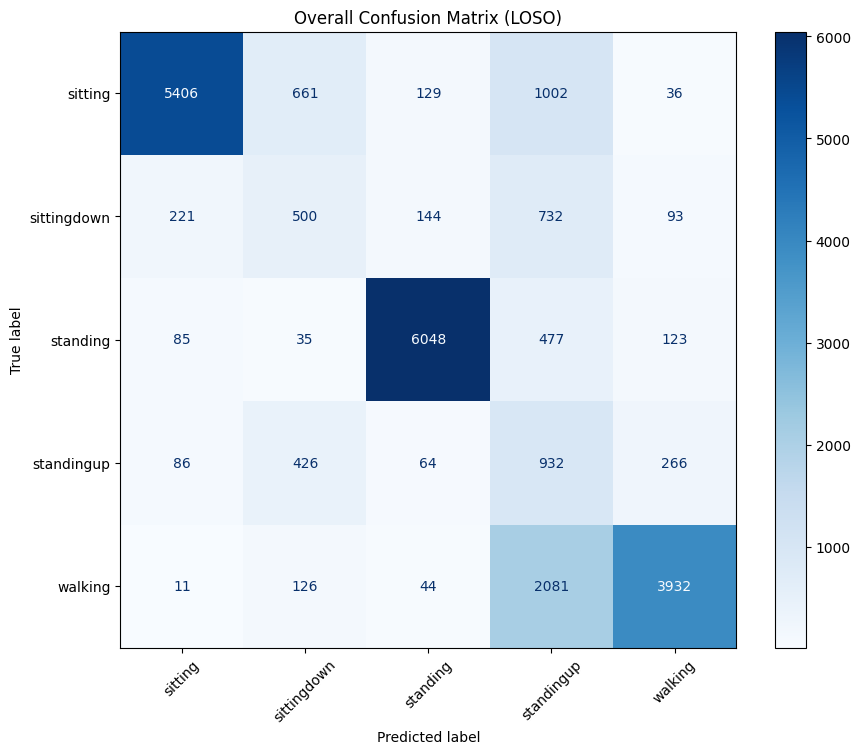

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from scipy.stats import iqr
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import shap

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load the dataset
dataset_path = '/content/drive/MyDrive/Colab/baseline.csv'
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found.")
    df = None

if df is not None:
    # Pre-processing: Gender encoding
    df = pd.get_dummies(df, columns=['gender'], drop_first=True)

    # 3. Windowing and Feature Extraction (Statistical Features)
    accel_cols = ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']
    static_features = ['user', 'gender_Woman', 'age', 'how_tall_in_meters', 'weight', 'body_mass_index', 'class']

    window_size = 8  # 1 second @ 8Hz
    overlap = 1
    step_size = window_size - overlap

    windowed_features_list = []
    print("Applying windowing and extracting statistical features (No Discretization)...")

    for user_id, user_data in df.groupby('user'):
        for i in range(0, len(user_data) - window_size + 1, step_size):
            window = user_data.iloc[i : i + window_size]
            features_dict = {}
            # Add static features
            for col in static_features:
                if col in window.columns:
                    features_dict[col] = window[col].iloc[0]

            # Extract statistical features for each accelerometer component
            for col in accel_cols:
                features_dict[f'{col}_mean'] = window[col].mean()
                features_dict[f'{col}_std'] = window[col].std()
                features_dict[f'{col}_min'] = window[col].min()
                features_dict[f'{col}_max'] = window[col].max()
                features_dict[f'{col}_median'] = window[col].median()
                features_dict[f'{col}_iqr'] = iqr(window[col])

            windowed_features_list.append(features_dict)

    windowed_df = pd.DataFrame(windowed_features_list)

    # Define features and target (raw windowed features)
    features_list = [col for col in windowed_df.columns if col not in ['user', 'class']]
    X_final = windowed_df[features_list]
    y_final = windowed_df['class']

    # 4. Leave-One-Subject-Out (LOSO) Cross-Validation
    unique_users = windowed_df['user'].unique()
    f1_scores_per_user = {}
    all_true_labels = []
    all_predictions = []

    print("\nStarting LOSO Cross-Validation...")

    for user_id in unique_users:
        train_df = windowed_df[windowed_df['user'] != user_id]
        test_df = windowed_df[windowed_df['user'] == user_id]

        X_train, y_train = train_df[features_list], train_df['class']
        X_test, y_test = test_df[features_list], test_df['class']

        clf = DecisionTreeClassifier(random_state=42)
        clf.fit(X_train, y_train)

        y_pred = clf.predict(X_test)

        f1 = f1_score(y_test, y_pred, average='weighted')
        f1_scores_per_user[user_id] = f1

        all_true_labels.extend(y_test)
        all_predictions.extend(y_pred)

    # 5. Print F1-Score Results
    print("\n--- LOSO Results (Raw Windowed Features) ---")
    for user, score in f1_scores_per_user.items():
        print(f"User {user}: F1-Score = {score:.4f}")

    overall_f1 = f1_score(all_true_labels, all_predictions, average='weighted')
    print(f"\nOVERALL WEIGHTED F1-SCORE: {overall_f1:.4f}")

    # 6. SHAP GLOBAL AND LOCAL ANALYSIS
    print("\nStarting SHAP Analysis (this may take a moment)...")

    # Train final model on all data for explanation
    final_model = DecisionTreeClassifier(random_state=42)
    final_model.fit(X_final, y_final)
    class_names = final_model.classes_

    explainer = shap.TreeExplainer(final_model)
    # Using a subset for SHAP calculation speed if dataset is large,
    # but here we use the full X_final for precise global mapping.
    shap_explanation = explainer(X_final)

    # A. Global Summary Plot (Multi-class)
    plt.figure(figsize=(12, 8))
    shap.summary_plot(explainer.shap_values(X_final), X_final, plot_type="bar", class_names=class_names, show=False)
    plt.title("Global Feature Importance (Total impact per Class)")
    plt.show()

    # B. Class-Specific Local/Global Impact
    # Slicing the explanation for each class
    for i, class_label in enumerate(class_names):
        print(f"\nVisualizing Top Features for Class: {class_label}")
        plt.figure(figsize=(10, 6))
        # shap_explanation[:, :, i] extracts SHAP values for the specific class
        shap.plots.beeswarm(shap_explanation[:, :, i], max_display=15, show=False)
        plt.title(f"Feature Impact for Class: {class_label}")
        plt.show()

    # C. Importance Ranking: Most vs Least Important Features
    # Calculate mean absolute SHAP across all samples and all classes
    if len(shap_explanation.values.shape) == 3:
        # Average across samples (0) and Classes (2)
        mean_abs_shap = np.abs(shap_explanation.values).mean(axis=(0, 2))
    else:
        # Alternative format for older SHAP versions
        shap_values_list = explainer.shap_values(X_final)
        mean_abs_shap = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values_list], axis=0)

    importance_df = pd.DataFrame({
        'Feature': features_list,
        'Importance': mean_abs_shap
    }).sort_values(by='Importance', ascending=False)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    # Top 20 Features
    sns.barplot(data=importance_df.head(20), x='Importance', y='Feature', palette='viridis', ax=ax1)
    ax1.set_title("Top 20 Most Important Features")

    # Bottom 20 Features
    sns.barplot(data=importance_df.tail(20), x='Importance', y='Feature', palette='rocket', ax=ax2)
    ax2.set_title("20 Least Important Features")

    plt.tight_layout()
    plt.show()

    # Final Confusion Matrix
    cm = confusion_matrix(all_true_labels, all_predictions, labels=class_names)
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title("Overall Confusion Matrix (LOSO)")
    plt.xticks(rotation=45)
    plt.show()